# Exercise: Matplotlib — Swiss EV Charging Stations

In this exercise you will create EDA plots using **Matplotlib** for the Swiss EV charging stations dataset. Use the object-oriented interface (`fig, ax = plt.subplots()`) throughout.

---
## Tasks
1. **Histogram**: plot the distribution of `power_kw` with 30 bins. Add x-label, y-label and title.
2. **Horizontal bar chart**: show the top 10 cities by station count (sorted descending).
3. **Box plot**: compare `power_kw` across the three `power_type` groups side by side.
4. **Scatter plot**: plot `voltage` vs. `power_kw`. Use different colours for each `power_type`.
5. **Pie chart**: show the share of each `plug_type`. Limit to the top 4 types, group the rest as 'Other'.
6. **Subplots (2×2)**: combine histogram, bar chart, box plot and scatter plot in a single figure.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../ev_charging_stations.csv')
print('Shape:', df.shape)
df.head(3)

Shape: (2442, 15)


,evse_id,station_name,street,city,postal_code,lat,lon,power_kw,power_type,amperage,voltage,plug_type,is_open_24h,renewable_energy,auth_mode
0,CH*CCI*E22078,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
1,CH*CCI*E22076,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
2,CH*CCI*E22079,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic


### Task 1 — Histogram of `power_kw`

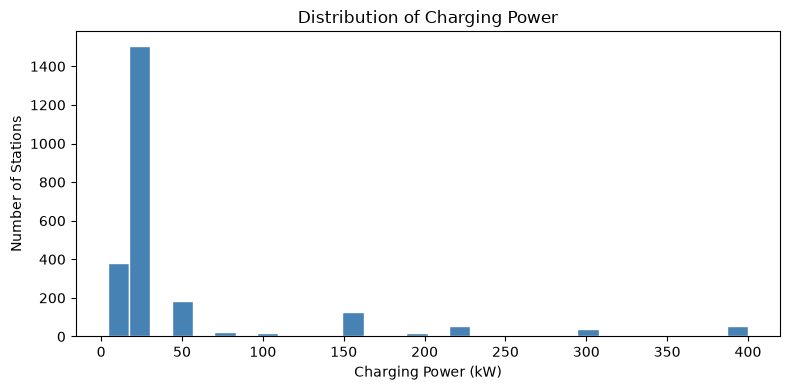

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))                                 #Abbildung (fig) und Zeichenfläche (ax) erstellen; figsize = Breite und Höhe in Zoll

ax.hist(df['power_kw'], bins=30, color='steelblue', edgecolor='white') #Histogramm der numerischen Spalte power_kw erstellen
                                                                       #bins=30: Wertebereich in 30 Intervalle unterteilen
                                                                       #color: Balkenfarbe; edgecolor: Farbe der Balkenumrandung
                                                                       #Balkenhöhe: Anzahl Beobachtungen pro Intervall

ax.set_xlabel('Charging Power (kW)')                                    #X-Achse beschriften (Ladeleistung)
ax.set_ylabel('Number of Stations')                                     #Y-Achse beschriften (Anzahl Ladestationen)
ax.set_title('Distribution of Charging Power') #Diagrammtitel festlegen

plt.tight_layout()                                                      #Abstände optimieren, damit Beschriftungen sichtbar bleiben
plt.show()                                                              #Histogramm anzeigen

#ANPASSEN: df und 'power_kw' an den verwendeten DataFrame und die numerische Spalte anpassen
#ANPASSEN: bins=30 an die gewünschte Anzahl Intervalle anpassen
#ANPASSEN: figsize=(8, 4), color und edgecolor bei Bedarf anpassen
#ANPASSEN: ax.set_xlabel(), ax.set_ylabel() und ax.set_title() passend beschriften
#NICHTS ANPASSEN: plt.subplots(), ax.hist(), plt.tight_layout() und plt.show() bleiben bei dieser Vorgehensweise gleich
#VORAUSSETZUNG: matplotlib.pyplot wurde als plt importiert und df ist geladen
#ACHTUNG: Die Anzahl Bins beeinflusst die Darstellung der Verteilung
#ERKENNTNIS: Histogramme zeigen Häufigkeiten numerischer Werte und helfen, Verteilung, Schiefe und Ausreisser zu erkennen

### Task 2 — Horizontal bar chart: top 10 cities

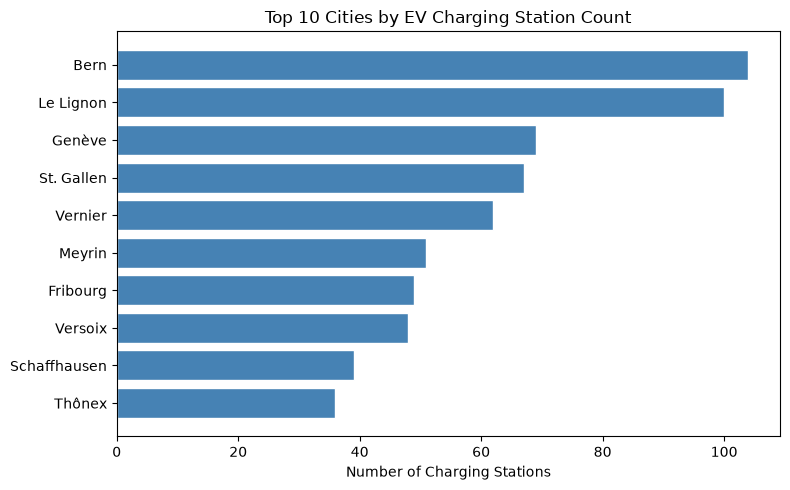

In [4]:
top10 = df['city'].value_counts().head(10).sort_values()                #Die 10 häufigsten Städte ermitteln und aufsteigend sortieren
                                                                        #value_counts(): Häufigkeiten pro Stadt zählen (absteigend)
                                                                        #head(10): Die 10 häufigsten Städte auswählen
                                                                        #sort_values(): Diese 10 Städte aufsteigend sortieren, damit die häufigste oben erscheint

fig, ax = plt.subplots(figsize=(8, 5))                                   #Abbildung (fig) und Zeichenfläche (ax) erstellen; Grösse in Zoll

ax.barh(top10.index, top10.values, color='steelblue', edgecolor='white') #Horizontales Balkendiagramm erstellen
                                                                         #top10.index: Städtenamen (Y-Achse)
                                                                         #top10.values: Anzahl Ladestationen (X-Achse)
                                                                         #color: Balkenfarbe; edgecolor: Umrandungsfarbe

ax.set_xlabel('Number of Charging Stations')                            #X-Achse beschriften
ax.set_title('Top 10 Cities by EV Charging Station Count')              #Diagrammtitel festlegen

plt.tight_layout()                                                      #Abstände und Beschriftungen optimieren
plt.show()                                                              #Diagramm anzeigen

#ANPASSEN: df und 'city' an den verwendeten DataFrame und die kategoriale Spalte anpassen
#ANPASSEN: head(10) an die gewünschte Anzahl Kategorien anpassen (z.B. head(5) für Top 5)
#ANPASSEN: figsize=(8, 5), color und edgecolor bei Bedarf anpassen
#ANPASSEN: ax.set_xlabel() und ax.set_title() passend zum Datensatz beschriften
#NICHTS ANPASSEN: value_counts(), sort_values(), ax.barh(), plt.tight_layout() und plt.show() bleiben bei dieser Vorgehensweise gleich
#VORAUSSETZUNG: matplotlib.pyplot wurde als plt importiert und df ist geladen
#ACHTUNG: value_counts() ignoriert fehlende Werte (NaN) standardmässig
#ERKENNTNIS: Die Balken zeigen die Häufigkeiten der 10 häufigsten Kategorien; die häufigste Kategorie steht oben

### Task 3 — Box plot: `power_kw` by `power_type`

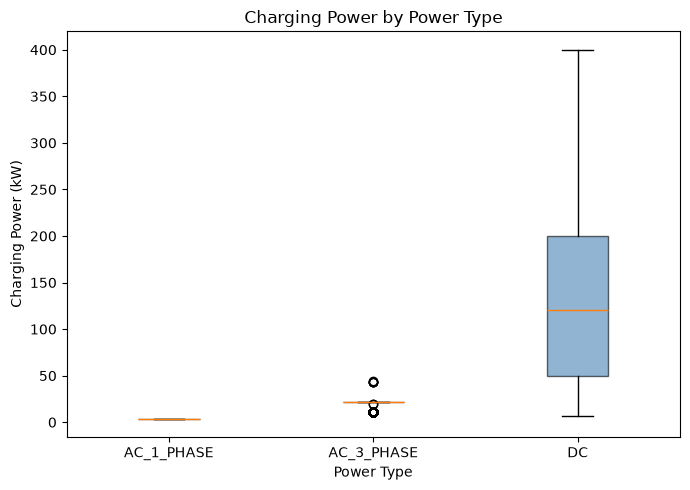

In [5]:
order = ['AC_1_PHASE', 'AC_3_PHASE', 'DC']                              #Gewünschte Reihenfolge der Kategorien im Boxplot festlegen

data = [df[df['power_type'] == t]['power_kw'].values for t in order]    #Ladeleistungen für jede Kategorie separat zusammenstellen
                                                                        #for t in order: Alle drei Kategorien nacheinander durchlaufen
                                                                        #df['power_type'] == t: Zeilen der aktuellen Kategorie identifizieren
                                                                        #df[...]: Nur Zeilen dieser Kategorie auswählen
                                                                        #['power_kw'].values: Numerische Ladeleistungen als NumPy-Array auslesen
                                                                        #Ergebnis: Liste mit drei Arrays, eines pro Ladeart

fig, ax = plt.subplots(figsize=(7, 5))                                  #Abbildung (fig) und Zeichenfläche (ax) erstellen; Grösse in Zoll

ax.boxplot(data, tick_labels=order, patch_artist=True,                  #Boxplot für die drei Kategorien erstellen
                                                                        #data: Liste der numerischen Werte pro Kategorie
                                                                        #tick_labels=order: Kategorien auf der X-Achse beschriften
                                                                        #patch_artist=True: Farbige Füllung der Boxen ermöglichen
           boxprops=dict(facecolor='steelblue', alpha=0.6))             #Darstellung der Boxen festlegen
                                                                        #facecolor='steelblue': Füllfarbe der Boxen
                                                                        #alpha=0.6: Transparenz der Boxen (0 bis 1)

ax.set_xlabel('Power Type')                                             #X-Achse beschriften (Ladearten)
ax.set_ylabel('Charging Power (kW)')                                    #Y-Achse beschriften (Ladeleistung)
ax.set_title('Charging Power by Power Type')                            #Diagrammtitel festlegen

plt.tight_layout()                                                      #Abstände optimieren
plt.show()                                                              #Boxplot anzeigen

#ANPASSEN: df an den verwendeten DataFrame anpassen
#ANPASSEN: 'power_type' an die gewünschte kategoriale Spalte anpassen
#ANPASSEN: 'power_kw' an die gewünschte numerische Spalte anpassen
#ANPASSEN: order an die vorhandenen Kategorien und ihre gewünschte Reihenfolge anpassen
#ANPASSEN: figsize=(7, 5), facecolor und alpha bei Bedarf anpassen
#ANPASSEN: ax.set_xlabel(), ax.set_ylabel() und ax.set_title() passend beschriften
#NICHTS ANPASSEN: Die List Comprehension, ax.boxplot(), plt.tight_layout() und plt.show() bleiben bei dieser Vorgehensweise gleich
#ACHTUNG: Die Kategorien in order müssen exakt mit den Werten in der Gruppierungsspalte übereinstimmen
#ERKENNTNIS: Median = Linie in der Box; IQR = Boxhöhe (Q3 - Q1); Whiskers = Streuungsbereich; einzelne Punkte = mögliche Ausreisser

### Task 4 — Scatter plot: `voltage` vs. `power_kw` coloured by `power_type`

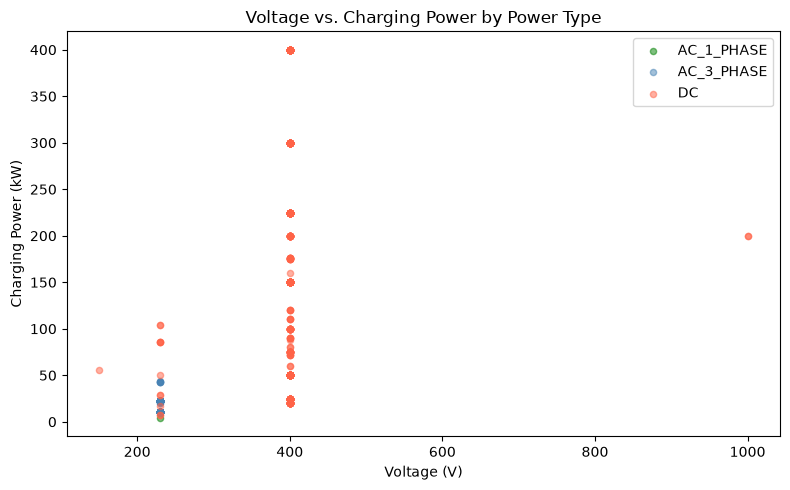

In [6]:
colors = {'AC_1_PHASE': 'green', 'AC_3_PHASE': 'steelblue', 'DC': 'tomato'} #Dictionary: Jeder Ladeart eine bestimmte Farbe zuweisen
                                                                            #Schlüssel = Kategorie; Wert = zugehörige Farbe

fig, ax = plt.subplots(figsize=(8, 5))                                      #Abbildung (fig) und Zeichenfläche (ax) erstellen; Grösse in Zoll

for ptype, grp in df.groupby('power_type'):                                 #Daten nach Ladeart gruppieren und jede Gruppe einzeln durchlaufen
                                                                            #ptype: Aktueller Kategoriename; grp: Zugehöriger Teil-DataFrame
    ax.scatter(grp['voltage'], grp['power_kw'],                             #Scatter Plot mit Spannung (X) und Ladeleistung (Y) erstellen
               label=ptype, color=colors[ptype], alpha=0.5, s=20)           #Darstellung der jeweiligen Gruppe festlegen
                                                                            #label=ptype: Kategoriename für die Legende
                                                                            #color=colors[ptype]: Farbe aus dem Dictionary anhand der Kategorie auswählen
                                                                            #alpha=0.5: Transparenz (0 bis 1); s=20: Punktgrösse

ax.set_xlabel('Voltage (V)')                                                #X-Achse beschriften
ax.set_ylabel('Charging Power (kW)')                                        #Y-Achse beschriften
ax.set_title('Voltage vs. Charging Power by Power Type')                    #Diagrammtitel festlegen
ax.legend()                                                                 #Legende mit den verschiedenen Ladearten anzeigen

plt.tight_layout()                                                          #Abstände optimieren
plt.show()                                                                  #Scatter Plot anzeigen

#ANPASSEN: df an den verwendeten DataFrame anpassen
#ANPASSEN: 'power_type' an die kategoriale Gruppierungsvariable anpassen
#ANPASSEN: 'voltage' und 'power_kw' an die numerischen X- und Y-Spalten anpassen
#ANPASSEN: colors an die vorhandenen Kategorien und gewünschten Farben anpassen
#ANPASSEN: figsize=(8, 5), alpha=0.5 und s=20 bei Bedarf anpassen
#ANPASSEN: Achsenbeschriftungen und Diagrammtitel passend zum Datensatz anpassen
#NICHTS ANPASSEN: groupby(), for-Schleife, ax.scatter(), ax.legend(), plt.tight_layout() und plt.show() bleiben bei dieser Vorgehensweise gleich
#VORAUSSETZUNG: df ist geladen und matplotlib.pyplot wurde als plt importiert
#ACHTUNG: Jede Kategorie aus power_type muss als Schlüssel im Dictionary colors vorhanden sein, sonst entsteht ein KeyError
#ERKENNTNIS: Individuelle Farben ermöglichen einen gezielten visuellen Vergleich verschiedener Kategorien

### Task 5 — Pie chart: share of `plug_type`

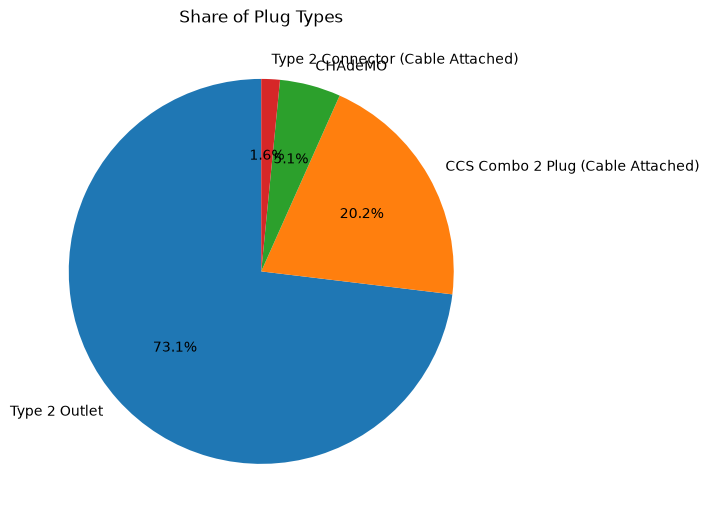

In [7]:
counts = df['plug_type'].value_counts()                                         #Häufigkeit jedes Steckertyps zählen (absteigend sortiert)
top4 = counts.head(4)                                                           #Die vier häufigsten Steckertypen auswählen
other = counts.iloc[4:].sum()                                                   #Alle übrigen Häufigkeiten ab dem 5. Steckertyp aufsummieren

if other > 0:                                                                   #Nur wenn weitere Steckertypen existieren
    top4['Other'] = other                                                       #Übrige Steckertypen als zusätzliche Kategorie 'Other' ergänzen

fig, ax = plt.subplots(figsize=(7, 7))                                          #Abbildung und Zeichenfläche erstellen; Grösse in Zoll
ax.pie(top4.values, labels=top4.index, autopct='%1.1f%%', startangle=90)        #Kreisdiagramm erstellen
                                                                                #top4.values: Häufigkeiten bestimmen die Grösse der Kreissegmente
                                                                                #labels=top4.index: Steckertypen als Beschriftungen anzeigen
                                                                                #autopct='%1.1f%%': Prozentwerte mit einer Nachkommastelle anzeigen
                                                                                #startangle=90: Kreisdiagramm bei 90° (oben) starten

ax.set_title('Share of Plug Types')                                             #Diagrammtitel festlegen
plt.tight_layout()                                                              #Abstände optimieren
plt.show()                                                                      #Kreisdiagramm anzeigen

#ANPASSEN: df und 'plug_type' an den DataFrame und die kategoriale Spalte anpassen
#ANPASSEN: head(4) und iloc[4:] gemeinsam ändern, falls eine andere Anzahl Top-Kategorien gewünscht ist
#ANPASSEN: figsize=(7, 7), autopct und startangle bei Bedarf anpassen
#ANPASSEN: ax.set_title() passend zum Datensatz beschriften
#NICHTS ANPASSEN: value_counts(), sum(), if other > 0, ax.pie(), plt.tight_layout() und plt.show() bleiben bei dieser Vorgehensweise gleich
#VORAUSSETZUNG: df ist geladen und matplotlib.pyplot wurde als plt importiert
#ACHTUNG: top4['Other'] = other kann eine pandas SettingWithCopyWarning auslösen; bei Bedarf counts.head(4).copy() verwenden
#ACHTUNG: value_counts() ignoriert fehlende Werte (NaN) standardmässig
#ERKENNTNIS: Ein Pie Chart zeigt relative Anteile eines Ganzen; alle dargestellten Segmente ergeben zusammen 100 %

### Task 6 — Combined 2×2 subplot figure

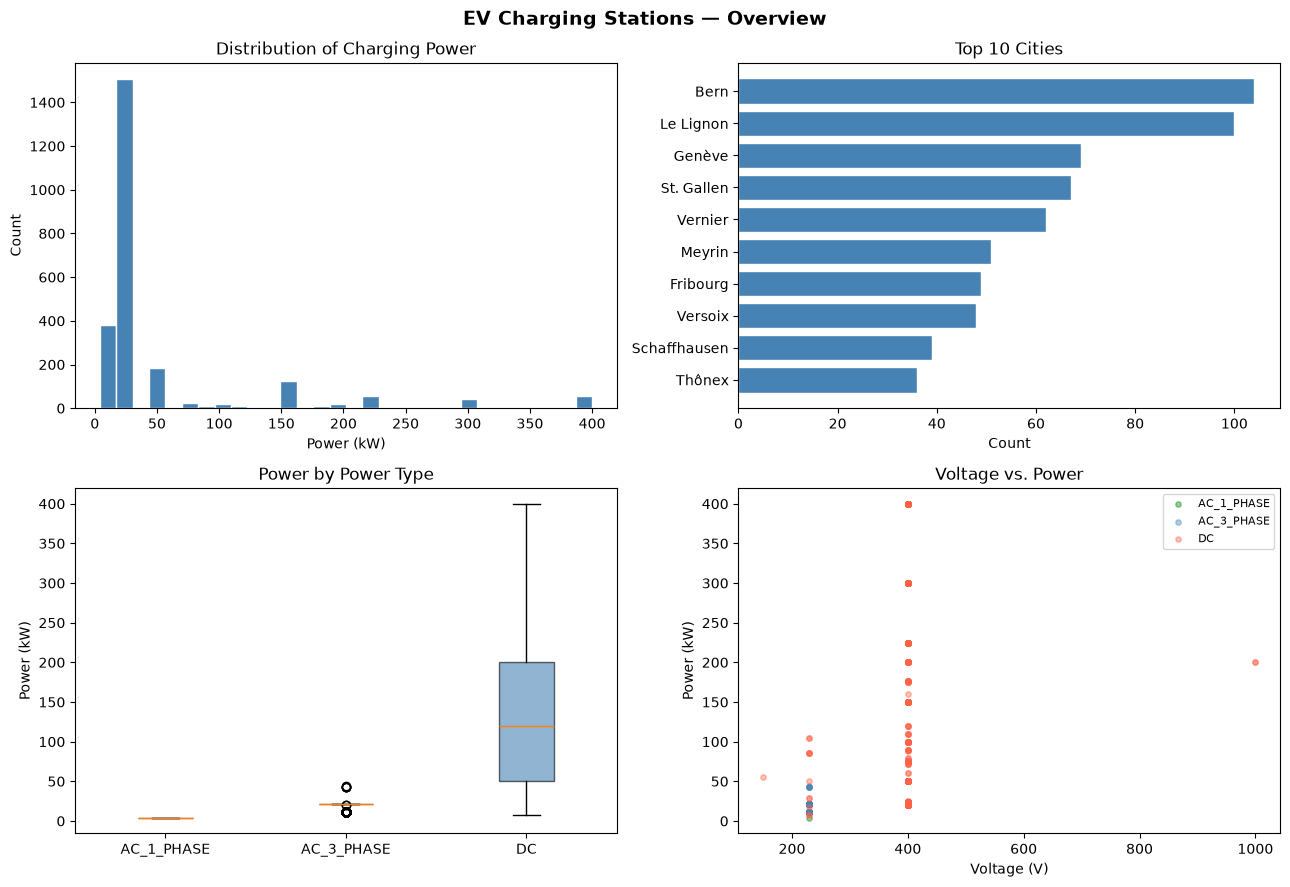

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))                                 #Abbildung mit 2 Zeilen und 2 Spalten (= 4 Diagramme) erstellen
                                                                                #fig: Gesamte Abbildung; axes: 2×2-Array mit vier Zeichenflächen
                                                                                #figsize: Gesamtgrösse in Zoll

# Histogram
axes[0, 0].hist(df['power_kw'], bins=30, color='steelblue', edgecolor='white')  #Histogramm oben links: Ladeleistung in 30 Intervalle unterteilen
axes[0, 0].set_title('Distribution of Charging Power')                          #Titel des ersten Diagramms
axes[0, 0].set_xlabel('Power (kW)')                                             #X-Achse: Ladeleistung
axes[0, 0].set_ylabel('Count')                                                  #Y-Achse: Häufigkeit

# Bar chart
top10 = df['city'].value_counts().head(10).sort_values()                        #10 häufigste Städte ermitteln und aufsteigend sortieren
axes[0, 1].barh(top10.index, top10.values, color='steelblue', edgecolor='white') #Balkendiagramm oben rechts: Städte (Y) und Häufigkeiten (X)
axes[0, 1].set_title('Top 10 Cities')                                           #Titel des zweiten Diagramms
axes[0, 1].set_xlabel('Count')                                                  #X-Achse: Anzahl Ladestationen

# Box plot
order = ['AC_1_PHASE', 'AC_3_PHASE', 'DC']                                      #Reihenfolge der Ladearten festlegen
data = [df[df['power_type'] == t]['power_kw'].values for t in order]            #Ladeleistungen je Ladeart als separate Arrays zusammenstellen
                                                                                #List Comprehension: Daten nach jeder Kategorie filtern
axes[1, 0].boxplot(data, tick_labels=order, patch_artist=True,                  #Boxplots unten links: Verteilung der Ladeleistung je Ladeart
                   boxprops=dict(facecolor='steelblue', alpha=0.6))             #Boxen füllen (patch_artist=True); Farbe und Transparenz festlegen
axes[1, 0].set_title('Power by Power Type')                                     #Titel des dritten Diagramms
axes[1, 0].set_ylabel('Power (kW)')                                             #Y-Achse: Ladeleistung

# Scatter plot
colors = {'AC_1_PHASE': 'green', 'AC_3_PHASE': 'steelblue', 'DC': 'tomato'}     #Jeder Ladeart eine Farbe zuweisen
for ptype, grp in df.groupby('power_type'):                                     #Daten nach Ladeart gruppieren; ptype = Kategorie, grp = zugehörige Daten
    axes[1, 1].scatter(grp['voltage'], grp['power_kw'],                         #Scatter Plot unten rechts: Spannung (X) gegen Ladeleistung (Y)
                       label=ptype, color=colors[ptype], alpha=0.4, s=15)       #Legendenname, Farbe, Transparenz und Punktgrösse
axes[1, 1].set_title('Voltage vs. Power')                                       #Titel des vierten Diagramms
axes[1, 1].set_xlabel('Voltage (V)')                                            #X-Achse: Spannung
axes[1, 1].set_ylabel('Power (kW)')                                             #Y-Achse: Ladeleistung
axes[1, 1].legend(fontsize=8)                                                   #Legende mit Ladearten anzeigen; Schriftgrösse 8

fig.suptitle('EV Charging Stations — Overview', fontsize=14, fontweight='bold') #Übergeordneter Titel für alle vier Diagramme
plt.tight_layout()                                                              #Abstände zwischen Diagrammen und Beschriftungen optimieren
plt.show()                                                                      #Gesamte Abbildung mit allen vier Diagrammen anzeigen

#ANPASSEN: df und die Spalten 'power_kw', 'city', 'power_type' und 'voltage' an den Datensatz anpassen
#ANPASSEN: order und colors an die vorhandenen Kategorien anpassen
#ANPASSEN: bins=30, head(10), figsize, Farben, Transparenz und Punktgrössen bei Bedarf anpassen
#ANPASSEN: Titel und Achsenbeschriftungen der einzelnen Diagramme passend wählen
#ANPASSEN: plt.subplots(2, 2) ändern, falls eine andere Anzahl Diagramme benötigt wird
#NICHTS ANPASSEN: Die grundsätzliche Vorgehensweise mit plt.subplots(), axes[Zeile, Spalte], plt.tight_layout() und plt.show()
#VORAUSSETZUNG: matplotlib.pyplot wurde als plt importiert und df ist geladen
#ACHTUNG: Die Indizierung beginnt bei 0 → axes[0, 0] = oben links; axes[1, 1] = unten rechts
#ACHTUNG: Bei einer anderen Subplot-Anordnung müssen die axes-Indizes entsprechend angepasst werden
#ERKENNTNIS: Subplots ermöglichen den direkten Vergleich mehrerer Diagramme innerhalb einer einzigen Figure

## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [9]:
import os, platform, socket
from platform import python_version
from datetime import datetime
print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('------------------------------------')

------------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-18 00:02:55
Python Version: 3.12.11
------------------------------------
